# Outspark: versión con herramientas del curso

Esta es la referencia académica vigente (21/10/2026). Usa listas de adyacencia, índices, listas de visitados, BFS y Graphviz. La fuente es el archivo original de amistades de Facebook New Orleans, MPI-SWS/WOSN 2009, previamente descomprimido como `facebook-links.txt`.

Fuentes de clase, celdas desde 1:
- Semana 4, `04_02_Lista_Adyacencia_CA.ipynb`: adyacencias y dibujo.
- Semana 5, `Tipos de Recorridos en MA y LA/01_2_BFS_y_Lista_de_Adyacencia_LA.ipynb`, celdas 4, 8 y 10: BFS, lectura y dibujo.
- Semana 6–7, `06_01_Ordenamieno_Topologico.ipynb`, celdas 4–6: labels, w2i y dibujo.
- Semana 5, `05_02_dijkstra_adj_list.ipynb`, celda 5: layout sfdp de Graphviz.

Adaptaciones: omitir duplicados del archivo original, usar un índice de lectura en la cola en lugar de `pop(0)`, registrar distancia por niveles y reiniciar BFS en los nodos pendientes para obtener componentes. Son adaptaciones de las técnicas del curso, no ejercicios idénticos del docente. No hay detección de comunidades por densidad ni medición de influencia.


In [1]:
"""Núcleo académico: Python básico, listas de adyacencia, BFS y Graphviz."""
import graphviz as gv


def leer_amistades(nombre):
    labels = []
    w2i = {}
    graph = []
    added = set()
    with open(nombre) as archivo:
        for linea in archivo:
            datos = linea.split()
            if not datos:
                continue
            a, b = int(datos[0]), int(datos[1])
            for usuario in [a, b]:
                if usuario not in w2i:
                    w2i[usuario] = len(labels)
                    labels.append(usuario)
                    graph.append([])
            u, v = w2i[a], w2i[b]
            if u != v and (u, v) not in added:
                graph[u].append(v)
                graph[v].append(u)
                added.add((u, v))
                added.add((v, u))
    return graph, labels, w2i


def bfs(graph, start):
    visited = [False] * len(graph)
    path = [-1] * len(graph)
    distance = [-1] * len(graph)
    queue = [start]
    visited[start] = True
    distance[start] = 0
    head = 0
    while head < len(queue):
        u = queue[head]
        head += 1
        for v in graph[u]:
            if not visited[v]:
                visited[v] = True
                path[v] = u
                distance[v] = distance[u] + 1
                queue.append(v)
    return path, distance


def componentes(graph):
    visited = [False] * len(graph)
    groups = []
    for start in range(len(graph)):
        if visited[start]:
            continue
        queue = [start]
        visited[start] = True
        head = 0
        while head < len(queue):
            u = queue[head]
            head += 1
            for v in graph[u]:
                if not visited[v]:
                    visited[v] = True
                    queue.append(v)
        groups.append(queue)
    return groups


def subgrafo(graph, labels, start, limit=45):
    selected = [start]
    for v in graph[start]:
        if len(selected) >= limit:
            break
        selected.append(v)
    indices = {}
    for i in range(len(selected)):
        indices[selected[i]] = i
    result = [[] for _ in selected]
    for u in selected:
        for v in graph[u]:
            if v in indices:
                result[indices[u]].append(indices[v])
    return result, [labels[u] for u in selected]


def subgrafo_bfs(graph, labels, start, limit=1500):
    selected = [start]
    visited = {start}
    head = 0
    while head < len(selected) and len(selected) < limit:
        u = selected[head]
        head += 1
        for v in sorted(graph[u], key=lambda index: labels[index]):
            if v not in visited:
                visited.add(v)
                selected.append(v)
                if len(selected) == limit:
                    break
    indices = {}
    for i in range(len(selected)):
        indices[selected[i]] = i
    result = [[] for _ in selected]
    for u in selected:
        for v in graph[u]:
            if v in indices:
                result[indices[u]].append(indices[v])
    return result, [labels[u] for u in selected]


def dibujar(graph, labels):
    drawing = gv.Graph("Amistades", engine="sfdp")
    drawing.graph_attr["overlap"] = "true" if len(graph) > 100 else "false"
    drawing.graph_attr["start"] = "7"
    drawing.graph_attr["size"] = "12,8!"
    for u in range(len(graph)):
        if len(graph) > 100:
            drawing.node(str(u), label="", shape="point", width="0.02")
        else:
            drawing.node(str(u), str(labels[u]), fontsize="8")
    added = set()
    for u in range(len(graph)):
        for v in graph[u]:
            if (u, v) not in added:
                drawing.edge(str(u), str(v))
                added.add((u, v))
                added.add((v, u))
    return drawing


In [2]:
G, labels, w2i = leer_amistades("facebook-links.txt")
groups = componentes(G)
print("Nodos:", len(G))
print("Aristas:", sum(len(vecinos) for vecinos in G) // 2)
print("Componentes conexas:", len(groups))
print("Mayor componente:", max(len(group) for group in groups))

semilla = w2i[1]
path, distance = bfs(G, semilla)
for salto in range(1, 4):
    nuevos = sum(d == salto for d in distance)
    acumulados = sum(0 < d <= salto for d in distance)
    print("Saltos:", salto, "nuevos:", nuevos, "acumulados sin semilla:", acumulados)


Nodos: 63731
Aristas: 817090
Componentes conexas: 144
Mayor componente: 63392
Saltos: 1 nuevos: 26 acumulados sin semilla: 26
Saltos: 2 nuevos: 1694 acumulados sin semilla: 1720
Saltos: 3 nuevos: 25649 acumulados sin semilla: 27369


El cálculo utiliza todo el grafo. La vista general representa un subgrafo inducido de 1 500 nodos elegidos por BFS. El detalle muestra al usuario 1 y hasta 44 vecinos. Ninguna disposición visual representa distancia social.


In [3]:
V, nombres_vista = subgrafo_bfs(G, labels, semilla)
print("Vista general:", len(V), "nodos y", sum(len(vecinos) for vecinos in V) // 2, "aristas")
dibujar(V, nombres_vista)


Vista general: 1500 nodos y 17174 aristas


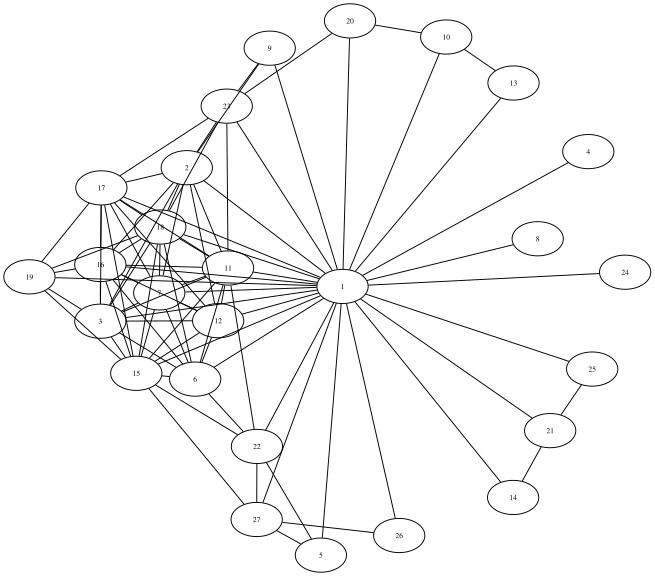

In [4]:
S, nombres = subgrafo(G, labels, semilla)
dibujar(S, nombres)
